# Capítulo 6: Algoritmos 3 – Resolución de problemas con algoritmos

---
# Unidad 32: Programación Dinámica (*Dynamic Programming*)

## 1. ¿Qué es la programación dinámica?

Es una técnica de diseño de algoritmos para resolver problemas **recursivos** que tienen **subproblemas que se repiten**. En lugar de resolver el mismo subproblema una y otra vez, se **resuelve una sola vez, se guarda el resultado** y se reutiliza cada vez que se necesite.

> **Idea en una frase:** *"Quien no recuerda el pasado está condenado a recalcularlo."*

**Analogía:** si te preguntan cuánto es `7 × 8` veinte veces, la primera vez lo calculas y las otras 19 lo recuerdas. Programación dinámica hace exactamente eso con los resultados intermedios.

## 2. La lógica: ¿cuándo aparece el problema?

Divide y Vencerás funciona muy bien cuando los subproblemas son **independientes** (en *Merge Sort*, cada mitad de la lista es distinta).

Pero hay problemas donde los subproblemas **se superponen** (*overlapping subproblems*): distintos caminos de la recursión piden **el mismo** cálculo. Entonces Divide y Vencerás lo resuelve cada vez desde cero y se desperdicia mucho trabajo.

La programación dinámica se aplica cuando el problema cumple dos propiedades:

| Propiedad | Significado |
|---|---|
| **Subproblemas superpuestos** | El mismo subproblema aparece muchas veces |
| **Subestructura óptima** | La solución del problema se construye a partir de las soluciones de sus subproblemas |

## 3. Método de uso (paso a paso)

1. **Identificar** que el problema se puede expresar de forma recursiva y que los subproblemas se repiten.
2. **Definir la relación recursiva** (cómo se calcula un caso a partir de los casos más pequeños) y los **casos base**.
3. **Elegir dónde guardar** los resultados: lista, diccionario o tabla (matriz).
4. **Resolver** con una de dos variantes:

| Variante | Cómo funciona | Dirección |
|---|---|---|
| **Memorización** (*memoization*) | Se escribe la recursión normal, pero **antes de calcular se consulta la tabla**; si ya está, se devuelve; si no, se calcula y se guarda | De arriba hacia abajo (*top-down*) |
| **Tabulación** | Se llena la tabla **desde los casos base** hacia el caso final, sin recursión | De abajo hacia arriba (*bottom-up*) |

## 4. Comparación con Divide y Vencerás

| | Divide y Vencerás | Programación Dinámica |
|---|---|---|
| Subproblemas | Independientes | Superpuestos |
| ¿Guarda resultados? | No | Sí (lista, diccionario o tabla) |
| Enfoque típico | Recursivo, de arriba hacia abajo | Memorizado (arriba-abajo) o tabulado (abajo-arriba) |
| Ejemplos | Merge Sort, Quick Sort, búsqueda binaria | Fibonacci eficiente, Triángulo de Pascal |

## 5. ¿Dónde se aplica?

- **Matemáticas:** Fibonacci, coeficientes binomiales, Triángulo de Pascal.
- **Optimización:** mochila (*knapsack*), cambio de monedas con el mínimo de monedas, ruta de costo mínimo.
- **Texto:** distancia entre cadenas (corrector ortográfico), subsecuencia común más larga (comparar versiones de un archivo, como hace `diff`).
- **Bioinformática:** alineamiento de secuencias de ADN.
- **Finanzas y logística:** decisiones por etapas (inventarios, planificación).
- **Videojuegos e IA:** cálculo de rutas y de la mejor estrategia por etapas.

## 6. Ventajas y desventajas

| Ventajas | Desventajas |
|---|---|
| Evita recalcular: reduce enormemente el trabajo repetido | Usa **memoria extra** para guardar la tabla |
| Convierte soluciones inviables en soluciones rápidas | Solo sirve si hay **subproblemas superpuestos**; si no, no aporta nada |
| Garantiza la **solución óptima** (a diferencia de Greedy, que a veces falla) | Requiere **pensar la relación recursiva** y los casos base: es más difícil de diseñar |
| La tabla permite **reconstruir** cómo se llegó a la solución | Puede guardar resultados que nunca se usan |
| El resultado es predecible y fácil de verificar | La tabulación puede ser menos intuitiva que la recursión directa |

> **Regla práctica:** si tu función recursiva se llama muchas veces con **los mismos argumentos**, es candidata a programación dinámica.

## 7. Cálculo de la secuencia de Fibonacci

La sucesión: `0, 1, 1, 2, 3, 5, 8, 13, 21, ...`, donde cada término es la suma de los dos anteriores.

$$F(0)=0,\qquad F(1)=1,\qquad F(n)=F(n-1)+F(n-2)$$

### 7.1 Versión recursiva directa (`fib1`)

Es la traducción literal de la fórmula. Además, contamos cuántas veces se llama a la función para **ver** el desperdicio.

In [31]:
llamadas = 0

def fib1(n):
    global llamadas
    llamadas += 1
    if n <= 1:
        return n
    return fib1(n - 1) + fib1(n - 2)


for n in [5, 10, 15, 20, 25]:
    llamadas = 0
    resultado = fib1(n)
    print(f"fib1({n:>2}) = {resultado:>6}   llamadas a la función: {llamadas:>7}")

fib1( 5) =      5   llamadas a la función:      15
fib1(10) =     55   llamadas a la función:     177
fib1(15) =    610   llamadas a la función:    1973
fib1(20) =   6765   llamadas a la función:   21891
fib1(25) =  75025   llamadas a la función:  242785


Observa cómo las llamadas **explotan** al crecer `n`: para pasar de `n = 20` a `n = 25` se multiplican por más de diez.

### ¿Por qué pasa? Subproblemas repetidos

Veamos el árbol de llamadas de `fib1(5)`. Cada valor repetido es trabajo desperdiciado:

```
                          fib(5)
                    /               \
              fib(4)                  fib(3)
             /      \                /      \
         fib(3)     fib(2)        fib(2)   fib(1)
         /    \     /   \         /   \
     fib(2) fib(1) fib(1) fib(0) fib(1) fib(0)
     /   \
  fib(1) fib(0)
```

`fib(3)` se calcula **2 veces**, `fib(2)` **3 veces**, `fib(1)` **5 veces**...

In [32]:
from collections import Counter

repeticiones = Counter()

def fib1_conteo(n):
    repeticiones[n] += 1
    if n <= 1:
        return n
    return fib1_conteo(n - 1) + fib1_conteo(n - 2)

fib1_conteo(10)
print("Veces que se calculó cada subproblema en fib(10):")
for k in sorted(repeticiones):
    print(f"  fib({k:>2}) -> {repeticiones[k]:>3} veces")

Veces que se calculó cada subproblema en fib(10):
  fib( 0) ->  34 veces
  fib( 1) ->  55 veces
  fib( 2) ->  34 veces
  fib( 3) ->  21 veces
  fib( 4) ->  13 veces
  fib( 5) ->   8 veces
  fib( 6) ->   5 veces
  fib( 7) ->   3 veces
  fib( 8) ->   2 veces
  fib( 9) ->   1 veces
  fib(10) ->   1 veces


### 7.2 Versión con memorización (`fib2`)

**Idea:** antes de calcular, **consultar la tabla**. Si el resultado ya está, se devuelve; si no, se calcula, **se guarda** y se devuelve.

Es la misma recursión de siempre con una tabla (diccionario) como memoria.

In [33]:
def fib2(n, memo=None):
    if memo is None:
        memo = {}
    if n in memo:                      # 1. consultar la tabla
        return memo[n]
    if n <= 1:                         # casos base
        resultado = n
    else:
        resultado = fib2(n - 1, memo) + fib2(n - 2, memo)
    memo[n] = resultado                # 2. guardar en la tabla
    return resultado


print(fib2(10))
print(fib2(50))
print(fib2(100))

55
12586269025
354224848179261915075


Contemos ahora las llamadas con memorización:

In [34]:
llamadas = 0

def fib2_conteo(n, memo):
    global llamadas
    llamadas += 1
    if n in memo:
        return memo[n]
    if n <= 1:
        memo[n] = n
    else:
        memo[n] = fib2_conteo(n - 1, memo) + fib2_conteo(n - 2, memo)
    return memo[n]


print(f"{'n':>3} | {'llamadas fib1':>14} | {'llamadas fib2':>14}")
for n in [2, 3, 4, 5, 10, 13, 15, 20, 25, 30, 35]:
    llamadas = 0
    fib1_llamadas = 0
    # contar fib1 sin tocar el contador global de fib2
    def contar(k):
        return 1 if k <= 1 else 1 + contar(k - 1) + contar(k - 2)
    fib1_llamadas = contar(n)
    llamadas = 0
    fib2_conteo(n, {})
    print(f"{n:>3} | {fib1_llamadas:>14} | {llamadas:>14}")

  n |  llamadas fib1 |  llamadas fib2
  2 |              3 |              3
  3 |              5 |              5
  4 |              9 |              7
  5 |             15 |              9
 10 |            177 |             19
 13 |            753 |             25
 15 |           1973 |             29
 20 |          21891 |             39
 25 |         242785 |             49
 30 |        2692537 |             59
 35 |       29860703 |             69


---
# Unidad 33: Retroceso (*Backtracking*)

## 1. ¿Qué es el backtracking?

Es una técnica para resolver problemas donde hay que **probar combinaciones de decisiones** hasta encontrar una solución. Se avanza tomando decisiones una por una y, cuando una decisión **lleva a un callejón sin salida, se retrocede** y se prueba otra opción.

> **Analogía:** estás en un laberinto con una tiza. Avanzas, marcas el camino y, si llegas a un muro, **vuelves hasta el último cruce** y pruebas otro pasillo.

El conjunto de todas las decisiones posibles forma un **árbol de espacio de búsqueda**: cada nodo es un estado parcial y cada rama es una decisión.

## 2. Búsqueda en profundidad (DFS, *Depth-First Search*)

Backtracking recorre el árbol con **búsqueda en profundidad**: se baja por un camino **hasta llegar al final** y solo entonces se retrocede para probar el siguiente. La **pila de llamadas** de la recursión es la que "recuerda" por dónde volver.

```
        A
      /   \\
     B     C
    / \\     \\
   D   E     F

Orden DFS: A → B → D → (retrocede) → E → (retrocede) → C → F
```

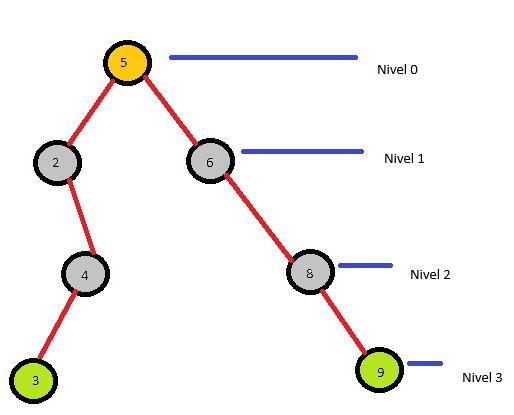

In [35]:
arbol = {
    "A": ["B", "C"],
    "B": ["D", "E"],
    "C": ["F"],
    "D": [],
    "E": [],
    "F": [],
}

def dfs(nodo, nivel=0):
    print("   " * nivel + nodo)
    for hijo in arbol[nodo]:
        dfs(hijo, nivel + 1)       # baja hasta el fondo
    # al terminar el ciclo, la función "retrocede" sola

dfs("A")

A
   B
      D
      E
   C
      F


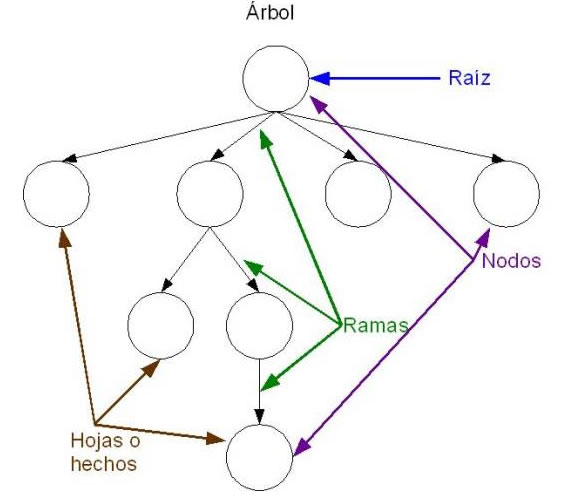

## 3. Estrategias clave

| Concepto | Significado |
|---|---|
| **Estado prometedor** (*promising*) | Un estado parcial que **todavía puede** llevar a una solución válida |
| **Poda** (*pruning*) | Si un estado **no es prometedor**, se corta esa rama y se retrocede **sin explorar** nada de lo que hay debajo |

La poda es lo que diferencia al backtracking de la **fuerza bruta** (probar absolutamente todo): al descartar ramas enteras temprano, se reduce drásticamente el espacio de búsqueda.

### Plantilla general

```python
def backtracking(estado):
    if es_solucion(estado):
        guardar(estado)
        return
    for opcion in opciones(estado):
        if es_prometedor(estado, opcion):     # poda: solo seguimos si vale la pena
            aplicar(estado, opcion)           # avanzar
            backtracking(estado)
            deshacer(estado, opcion)          # retroceder
```

## 4. Ejemplo sencillo: ¿qué monedas suman exactamente el monto?

**Problema:** tenemos monedas/billetes con ciertos valores y cada uno se puede usar **una sola vez**. ¿Qué combinaciones suman **exactamente** un monto objetivo?

Por ejemplo, con los valores `[2, 3, 5, 4]` y objetivo `9`:

- `2 + 3 + 4 = 9` ✔
- `5 + 4 = 9` ✔

**Decisión en cada paso:** para cada valor, ¿lo **incluyo** o lo **dejo fuera**?

```
                       (suma 0)
                  /               \
           incluir 2             no incluir 2
            (suma 2)              (suma 0)
           /       \             /        \
      incluir 3  no incluir 3   ...        ...
```

| Concepto | En este problema |
|---|---|
| **Estado** | La suma acumulada y los valores elegidos hasta ahora |
| **Prometedor** | La suma actual **no supera** el objetivo |
| **Poda** | Si la suma ya **se pasó** del objetivo, no tiene sentido seguir agregando valores |
| **Solución** | La suma es **exactamente** el objetivo |
| **Retroceso** | Quitar el último valor elegido (`pop`) y probar sin él |

In [36]:
def suma_exacta(valores, objetivo):
    soluciones = []
    elegidos = []

    def explorar(i, suma): # i es posicion y suma el acumulado de los nros elegidos
        # Poda: si ya nos pasamos, esta rama no sirve
        if suma > objetivo:
            return
        # Solución encontrada
        if suma == objetivo:
            soluciones.append(elegidos[:])
            return
        # Ya no hay más valores que probar
        if i == len(valores):
            return

        # Opción 1: incluir valores[i]
        elegidos.append(valores[i])
        explorar(i + 1, suma + valores[i])
        elegidos.pop()                      # retroceso: deshacer la decisión

        # Opción 2: no incluir valores[i]
        explorar(i + 1, suma)

    explorar(0, 0)
    return soluciones


print(suma_exacta([2, 3, 5, 4], 9))

[[2, 3, 4], [5, 4]]


### Seguimiento paso a paso

Esta versión imprime cada decisión, la sangría muestra la profundidad del árbol y marca dónde ocurre la **poda** y dónde se **retrocede**.

In [37]:
def suma_exacta_traza(valores, objetivo):
    elegidos = []

    def explorar(i, suma, nivel):
        sangria = "   " * nivel
        print(f"{sangria}elegidos={elegidos} suma={suma}")
        if suma > objetivo:
            print(f"{sangria}  X  PODA: {suma} > {objetivo}, se descarta esta rama")
            return
        if suma == objetivo:
            print(f"{sangria}  ✔  SOLUCIÓN: {elegidos}")
            return
        if i == len(valores):
            print(f"{sangria}  -  sin más valores, retrocede")
            return

        elegidos.append(valores[i])
        explorar(i + 1, suma + valores[i], nivel + 1)
        elegidos.pop()
        explorar(i + 1, suma, nivel + 1)

    explorar(0, 0, 0)

suma_exacta_traza([2, 3, 5, 4], 9)

elegidos=[] suma=0
   elegidos=[2] suma=2
      elegidos=[2, 3] suma=5
         elegidos=[2, 3, 5] suma=10
           X  PODA: 10 > 9, se descarta esta rama
         elegidos=[2, 3] suma=5
            elegidos=[2, 3, 4] suma=9
              ✔  SOLUCIÓN: [2, 3, 4]
            elegidos=[2, 3] suma=5
              -  sin más valores, retrocede
      elegidos=[2] suma=2
         elegidos=[2, 5] suma=7
            elegidos=[2, 5, 4] suma=11
              X  PODA: 11 > 9, se descarta esta rama
            elegidos=[2, 5] suma=7
              -  sin más valores, retrocede
         elegidos=[2] suma=2
            elegidos=[2, 4] suma=6
              -  sin más valores, retrocede
            elegidos=[2] suma=2
              -  sin más valores, retrocede
   elegidos=[] suma=0
      elegidos=[3] suma=3
         elegidos=[3, 5] suma=8
            elegidos=[3, 5, 4] suma=12
              X  PODA: 12 > 9, se descarta esta rama
            elegidos=[3, 5] suma=8
              -  sin más valores, ret

### ¿Cuánto ayuda la poda?

Comparemos cuántos estados se visitan **con** poda y **sin** poda, usando valores del 1 al 18 y objetivo 20.

In [38]:
def contar_estados(valores, objetivo, con_poda):
    visitados = 0

    def explorar(i, suma):
        nonlocal visitados
        visitados += 1
        if con_poda and suma > objetivo:      # poda
            return
        if i == len(valores):
            return
        explorar(i + 1, suma + valores[i])    # incluir
        explorar(i + 1, suma)                 # no incluir

    explorar(0, 0)
    return visitados


valores = list(range(1, 19))
sin_poda = contar_estados(valores, 20, con_poda=False)
con_poda = contar_estados(valores, 20, con_poda=True)

print(f"Sin poda: {sin_poda:>9} estados visitados")
print(f"Con poda: {con_poda:>9} estados visitados")
print(f"La poda evitó visitar el {100 * (1 - con_poda / sin_poda):.1f}% de los estados")

Sin poda:    524287 estados visitados
Con poda:      6407 estados visitados
La poda evitó visitar el 98.8% de los estados


## 5. Aplicación práctica: el ratón en el laberinto

**Problema:** un ratón está en la entrada de un laberinto (matriz) y debe llegar a la salida.

- `0` = camino libre
- `1` = muro
- El ratón se mueve en 4 direcciones: arriba, abajo, izquierda, derecha.

**Estrategia (DFS + retroceso):**

1. Desde la casilla actual, probar cada dirección.
2. Si la casilla es un **muro**, está **fuera** del laberinto o **ya se visitó**, no es prometedora (poda).
3. Si no, marcarla como parte del camino y seguir.
4. Si ninguna dirección funciona (**callejón sin salida**), **desmarcar** la casilla y retroceder.

In [39]:
def resolver_laberinto(laberinto):
    filas, cols = len(laberinto), len(laberinto[0])
    salida = (filas - 1, cols - 1)
    camino = []
    visitado = set()

    def prometedora(f, c):
        return (0 <= f < filas and 0 <= c < cols     # dentro del laberinto
                and laberinto[f][c] == 0             # no es muro
                and (f, c) not in visitado)          # no se ha pisado

    def explorar(f, c):
        visitado.add((f, c))
        camino.append((f, c))                        # avanzar

        if (f, c) == salida:
            return True

        # Direcciones: derecha, abajo, izquierda, arriba
        for df, dc in [(0, 1), (1, 0), (0, -1), (-1, 0)]:
            nf = f + df
            nc = c + dc
            if prometedora(nf, nc):
                if explorar(nf, nc):
                    return True

        camino.pop()                                  # callejón sin salida: retrocede
        return False

    if laberinto[0][0] == 0 and explorar(0, 0):
        return camino
    return None


laberinto = [
    [0, 1, 0, 0, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 0, 1, 0],
    [1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0],
]

camino = resolver_laberinto(laberinto)
print("Camino:", camino)

Camino: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4)]


In [40]:
def dibujar(laberinto, camino):
    ruta = set(camino or [])
    for f, fila in enumerate(laberinto):
        linea = ""
        for c, celda in enumerate(fila):
            if (f, c) in ruta:
                linea += " * "
            elif celda == 1:
                linea += "###"
            else:
                linea += " . "
        print(linea)

dibujar(laberinto, camino)

 * ### .  .  . 
 * ### . ### . 
 *  *  * ### . 
###### * ### . 
 .  .  *  *  * 


Referencias: `###` muro, ` . ` camino libre, ` * ` camino encontrado por el ratón.

### Laberinto sin salida

In [41]:
sin_salida = [
    [0, 0, 1],
    [1, 1, 1],
    [0, 0, 0],
]
print(resolver_laberinto(sin_salida))   # None

None


---
# Resumen

| Técnica | Idea principal | Ejemplos de la unidad |
|---|---|---|
| **Programación dinámica** | Guardar los resultados de subproblemas repetidos para no recalcularlos | Fibonacci, Triángulo de Pascal, coeficientes binomiales |
| **Backtracking** | Probar decisiones en profundidad y retroceder cuando una no lleva a solución | Suma exacta de monedas, ratón en el laberinto |

**Para recordar**

- Programación dinámica: *subproblemas repetidos → guardar → reutilizar* (memorización arriba-abajo o tabulación abajo-arriba).
- Backtracking: *elegir → explorar → deshacer*, con **poda** para descartar ramas que no son prometedoras.
- Divide y Vencerás, programación dinámica y backtracking comparten la recursión, pero resuelven problemas de naturaleza distinta.